#  AI-Based Crop-Safe Path Planning for an Autonomous Potato-Field Robot


## 👥 Group Members & Responsibilities

| # | Name | Roll Number | Responsibility |
|---|------|-------------|----------------|
| 1 | Nakul Bhadade | BT24CSA047 | Task 1 & Task 2 – Field environment design and problem formulation |
| 2 | Pranjal Baghel | BT24CSA052 | Task 3 (Part A) – BFS and DFS implementation |
| 3 | Ness Dubey | BT24CSA053 | Task 3 (Part B) – Greedy Best-First Search and heuristic design |
| 4 | Siddhi Dhoke | BT24CSA050 | Task 3 (Part C) & Task 4 – A* implementation and crop-safe path cost |
| 5 | Lakshuki Hatwar | BT24CSA063 | Task 5 & Task 6 – Obstacle detection, replanning, performance evaluation |


---

## 📋 Assignment Overview

An autonomous robot used for **potato-field monitoring** must travel between crop rows, visit monitoring locations, and avoid damaging plants or hitting obstacles. We model the field as a **2D grid** and apply AI search techniques to plan an optimal route.

| Task | Description |
|------|-------------|
| 1 | 2D potato-field grid construction with visualization |
| 2 | Formal problem formulation |
| 3 | BFS, DFS, Greedy Best-First, and A* Search |
| 4 | Crop-safe path planning with penalty cost |
| 5 | Obstacle detection and dynamic replanning |
| 6 | Performance comparison and evaluation |

---
## 📦 Imports & Setup

We use standard Python libraries:
- `numpy` – grid operations
- `matplotlib` – visualizations and screenshots
- `collections` – FIFO queue for BFS
- `heapq` – priority queue for Greedy / A*
- `time` – execution time measurement

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
import collections
import heapq
import time
import os

os.makedirs('screenshots', exist_ok=True)

print('✅ All libraries imported successfully!')
print('📂 Screenshots will be saved to: ./screenshots/')

✅ All libraries imported successfully!
📂 Screenshots will be saved to: ./screenshots/


---
## 🌾 TASK 1 – Field Environment
We model the potato field as a **10×10 2D grid**. Each cell has a type:

| Cell Type | Code | Description | Colour |
|-----------|------|-------------|--------|
| Free Path | 0 | Robot can travel freely | White |
| Potato Row | 1 | Actual crop rows — robot must NOT enter | Dark Green |
| Crop-Protected Region | 2 | Buffer zone — robot avoids or pays penalty | Light Green |
| Obstacle | 3 | Stones / tools — robot must NOT enter | Red |
| Start | 4 | Robot's starting position | Blue |
| Goal | 5 | Robot's destination | Gold |

**Movement:** The robot moves in **4 directions** — Up, Down, Left, Right — one cell at a time. No diagonal movement.

In [2]:
#  TASK 1 – Field Environment Design

# ── Cell type constants ──────────────────────────────────────
FREE        = 0   # Safe travel path
POTATO_ROW  = 1   # Crop row (BLOCKED)
CROP_ZONE   = 2   # Crop-protection buffer (PENALTY = 3)
OBSTACLE    = 3   # Hard obstacle (BLOCKED)
START_CELL  = 4   # Robot start
GOAL_CELL   = 5   # Robot destination

# ── Movement directions: (row_delta, col_delta) ──────────────
DIRECTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # Up, Down, Left, Right

# ── Shared colour map for all visualizations ─────────────────
VIZ_COLORS = ['#FFFFFF', '#228B22', '#90EE90', '#CC0000', '#1565C0', '#FFD700']
VIZ_CMAP   = ListedColormap(VIZ_COLORS)
VIZ_BOUNDS = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5]
VIZ_NORM   = BoundaryNorm(VIZ_BOUNDS, VIZ_CMAP.N)
CELL_LABELS = {FREE: '', POTATO_ROW: 'P', CROP_ZONE: 'C',
               OBSTACLE: 'X', START_CELL: 'S', GOAL_CELL: 'G'}

# ── Define the 10×10 Potato Field Grid ──────────────────────
# 0=free, 1=potato row, 2=crop-protected, 3=obstacle, 4=start, 5=goal
FIELD = np.array([
    [4, 0, 0, 1, 1, 0, 0, 0, 0, 0],   # Row 0  — Start at (0,0)
    [0, 2, 0, 1, 1, 0, 3, 0, 0, 0],   # Row 1  — crop-zone, potato rows, obstacle
    [0, 2, 0, 0, 0, 0, 3, 0, 2, 0],   # Row 2
    [0, 0, 0, 1, 1, 0, 0, 0, 2, 0],   # Row 3
    [0, 0, 2, 1, 1, 0, 0, 0, 0, 0],   # Row 4
    [0, 0, 2, 0, 0, 0, 1, 1, 0, 0],   # Row 5
    [0, 0, 0, 0, 3, 0, 1, 1, 0, 0],   # Row 6  — obstacle
    [0, 3, 0, 0, 0, 0, 0, 2, 0, 0],   # Row 7  — obstacle
    [0, 0, 0, 0, 0, 0, 0, 2, 0, 0],   # Row 8
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 5],   # Row 9  — Goal at (9,9)
], dtype=int)

START    = (0, 0)    # Top-left corner
GOAL     = (9, 9)    # Bottom-right corner
ROWS, COLS = FIELD.shape

print(f'🌾 Field size : {ROWS}×{COLS} grid  ({ROWS*COLS} total cells)')
print(f'🤖 Start      : {START}')
print(f'🎯 Goal       : {GOAL}')
print()
print('Raw grid values:')
print(FIELD)

🌾 Field size : 10×10 grid  (100 total cells)
🤖 Start      : (0, 0)
🎯 Goal       : (9, 9)

Raw grid values:
[[4 0 0 1 1 0 0 0 0 0]
 [0 2 0 1 1 0 3 0 0 0]
 [0 2 0 0 0 0 3 0 2 0]
 [0 0 0 1 1 0 0 0 2 0]
 [0 0 2 1 1 0 0 0 0 0]
 [0 0 2 0 0 0 1 1 0 0]
 [0 0 0 0 3 0 1 1 0 0]
 [0 3 0 0 0 0 0 2 0 0]
 [0 0 0 0 0 0 0 2 0 0]
 [0 0 0 0 0 0 0 0 0 5]]


💾 Saved: screenshots/task1_field_grid.png


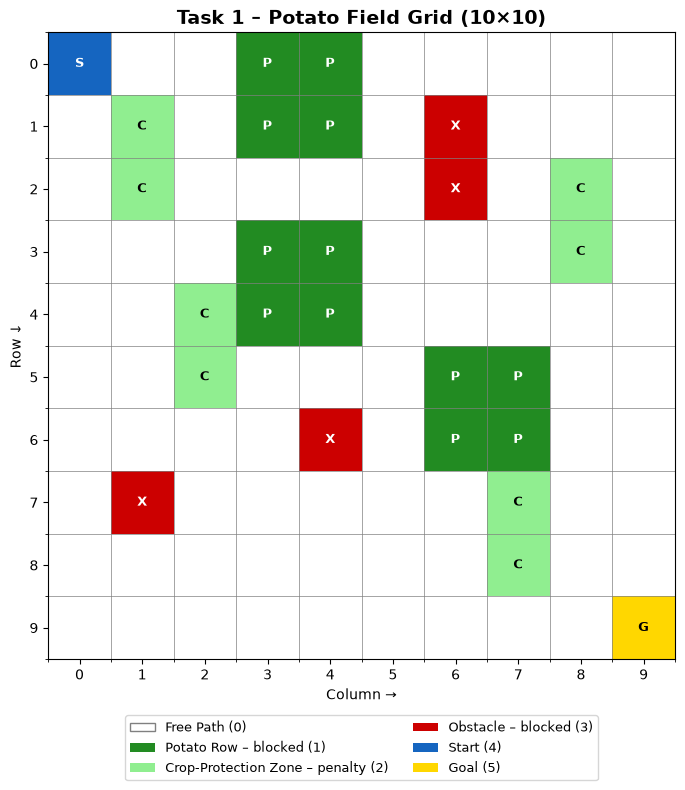

In [3]:
# ── Visualization Helper ─────────────────────────────────────
def draw_grid(ax, grid, path=None):
    """Draw the grid on a matplotlib Axes. Optional path drawn in orange."""
    nr, nc = grid.shape
    ax.imshow(grid, cmap=VIZ_CMAP, norm=VIZ_NORM, origin='upper')
    ax.set_xticks(np.arange(-0.5, nc, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, nr, 1), minor=True)
    ax.grid(which='minor', color='gray', linewidth=0.5)
    ax.set_xticks(np.arange(0, nc))
    ax.set_yticks(np.arange(0, nr))
    for r in range(nr):
        for c in range(nc):
            lbl = CELL_LABELS.get(grid[r, c], '')
            if lbl:
                ax.text(c, r, lbl, ha='center', va='center', fontsize=9,
                        fontweight='bold',
                        color='white' if grid[r, c] in [POTATO_ROW, OBSTACLE, START_CELL] else 'black')
    if path and len(path) > 1:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        ax.plot(pc, pr, 'o-', color='orange', linewidth=2.5, markersize=6, zorder=5)

def field_legend():
    """Return standard legend patches."""
    return [
        mpatches.Patch(facecolor='#FFFFFF', edgecolor='gray', label='Free Path (0)'),
        mpatches.Patch(facecolor='#228B22', label='Potato Row – blocked (1)'),
        mpatches.Patch(facecolor='#90EE90', label='Crop-Protection Zone – penalty (2)'),
        mpatches.Patch(facecolor='#CC0000', label='Obstacle – blocked (3)'),
        mpatches.Patch(facecolor='#1565C0', label='Start (4)'),
        mpatches.Patch(facecolor='#FFD700', label='Goal (5)'),
    ]

# ── Show the base field ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 8))
draw_grid(ax, FIELD)
ax.legend(handles=field_legend(), loc='upper center',
          bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9)
ax.set_title('Task 1 – Potato Field Grid (10×10)', fontsize=14, fontweight='bold')
ax.set_xlabel('Column →');  ax.set_ylabel('Row ↓')
plt.tight_layout()
plt.savefig('screenshots/task1_field_grid.png', dpi=120, bbox_inches='tight')
print('💾 Saved: screenshots/task1_field_grid.png')
plt.show()

---
## 📐 TASK 2 – Problem Formulation
We describe the path-planning problem as a formal **state-space search problem**:

| Component | Definition |
|-----------|------------|
| **Initial State** | Robot at cell `(0, 0)` |
| **State Space** | All `(row, col)` pairs where `0 ≤ row < 10`, `0 ≤ col < 10` |
| **Actions** | Move Up / Down / Left / Right (4-directional, one cell) |
| **Transition Model** | `result(state, action)` → new `(row, col)` if valid & passable |
| **Goal Test** | `state == (9, 9)` |
| **Path-Cost** | Sum of step costs: free cell = **1**, crop-zone = **3** (penalty) |
| **Passable Cells** | FREE (0), CROP_ZONE (2), START (4), GOAL (5) |
| **Blocked Cells** | POTATO_ROW (1), OBSTACLE (3) — robot must NEVER enter |

The **crop-zone penalty of 3** encourages the robot to find paths that keep a safe distance from the protected crops. If a free-path detour exists with lower total cost, A* will prefer it.

In [4]:
#  TASK 2 – Problem Formulation: Core Helper Functions

def is_valid(row, col, grid):
    """
    Returns True if (row, col) is inside the grid bounds
    AND is a passable cell (not POTATO_ROW or OBSTACLE).
    Works for grids of any size (uses grid.shape, not global ROWS/COLS).
    """
    nr, nc = grid.shape
    if row < 0 or row >= nr or col < 0 or col >= nc:
        return False
    return grid[row, col] not in [POTATO_ROW, OBSTACLE]

def step_cost(row, col, grid):
    """
    Path-cost function: cost of entering cell (row, col).
    - CROP_ZONE (2) → cost 3  (penalty: too close to protected crops)
    - All other passable cells → cost 1  (normal travel)
    """
    return 3 if grid[row, col] == CROP_ZONE else 1

def get_neighbors(row, col, grid):
    """
    Transition model: returns list of (new_row, new_col, cost) for
    all valid actions from (row, col).
    """
    neighbors = []
    for dr, dc in DIRECTIONS:
        nr, nc = row + dr, col + dc
        if is_valid(nr, nc, grid):
            neighbors.append((nr, nc, step_cost(nr, nc, grid)))
    return neighbors

def path_cost(path, grid):
    """Total cost of a path (list of (row,col) tuples)."""
    if path is None:
        return float('inf')
    return sum(step_cost(r, c, grid) for r, c in path[1:])   # skip start cell

# ── Problem formulation summary ───────────────────────────────
print('=' * 55)
print('       PROBLEM FORMULATION SUMMARY')
print('=' * 55)
print(f'  Initial State  : {START}')
print(f'  Goal State     : {GOAL}')
print(f'  Grid Size      : {ROWS} × {COLS} = {ROWS*COLS} states')
print(f'  Actions        : Up, Down, Left, Right (4-directional)')
print(f'  Blocked Cells  : POTATO_ROW (1), OBSTACLE (3)')
print(f'  Step Cost      : Free=1, Crop-Zone=3 (penalty)')
print('=' * 55)
print()
print(f'Valid neighbours of Start {START}:')
for r, c, cost in get_neighbors(*START, FIELD):
    print(f'  → ({r},{c})  cell_type={FIELD[r,c]}  step_cost={cost}')

       PROBLEM FORMULATION SUMMARY
  Initial State  : (0, 0)
  Goal State     : (9, 9)
  Grid Size      : 10 × 10 = 100 states
  Actions        : Up, Down, Left, Right (4-directional)
  Blocked Cells  : POTATO_ROW (1), OBSTACLE (3)
  Step Cost      : Free=1, Crop-Zone=3 (penalty)

Valid neighbours of Start (0, 0):
  → (1,0)  cell_type=0  step_cost=1
  → (0,1)  cell_type=0  step_cost=1


---
## 🔍 TASK 3 – Search Algorithms

We implement **four** search algorithms across Members 2, 3, 4.

### Heuristic (used by Greedy & A*)

We use the **Manhattan distance** heuristic:
$$h(n) = |row_n - row_{goal}| + |col_n - col_{goal}|$$

This is **admissible** because:
- The robot moves only in 4 directions, one cell at a time
- Manhattan distance is the minimum possible steps in any obstacle-free 4-directional grid
- It never **overestimates** the true remaining cost → A* is **guaranteed optimal**
- It is also **consistent** (monotone): $h(n) \leq cost(n, n') + h(n')$ for any successor $n'$

In [5]:
#  TASK 3 (Part A) – BFS & DFS

def bfs(grid, start, goal):
    """
    Breadth-First Search (BFS)
    ─────────────────────────
    Data structure : FIFO queue (collections.deque)
    Strategy       : Explores level by level (shallowest nodes first)
    Optimal?       : YES — finds shortest path (fewest steps) for uniform costs
    Complete?      : YES — always finds a solution if one exists
    Space          : O(b^d) where b=branching factor, d=depth

    Returns: (path, nodes_expanded, time_ms)
    """
    t0 = time.perf_counter()
    queue    = collections.deque([(start, [start])])   # (state, path_so_far)
    visited  = {start}
    expanded = 0

    while queue:
        (r, c), path = queue.popleft()   # Dequeue from FRONT (FIFO)
        expanded += 1

        if (r, c) == goal:
            return path, expanded, (time.perf_counter() - t0) * 1000

        for nr, nc, _ in get_neighbors(r, c, grid):
            if (nr, nc) not in visited:
                visited.add((nr, nc))
                queue.append(((nr, nc), path + [(nr, nc)]))

    return None, expanded, (time.perf_counter() - t0) * 1000


def dfs(grid, start, goal):
    """
    Depth-First Search (DFS)
    ────────────────────────
    Data structure : LIFO stack (Python list)
    Strategy       : Explores as deep as possible before backtracking
    Optimal?       : NO — may find a longer path
    Complete?      : YES — with visited set (finite graph, no cycles)
    Space          : O(bm) where m=max depth

    Returns: (path, nodes_expanded, time_ms)
    """
    t0 = time.perf_counter()
    stack    = [(start, [start])]         # (state, path_so_far)
    visited  = {start}
    expanded = 0

    while stack:
        (r, c), path = stack.pop()        # Pop from TOP (LIFO)
        expanded += 1

        if (r, c) == goal:
            return path, expanded, (time.perf_counter() - t0) * 1000

        for nr, nc, _ in get_neighbors(r, c, grid):
            if (nr, nc) not in visited:
                visited.add((nr, nc))
                stack.append(((nr, nc), path + [(nr, nc)]))

    return None, expanded, (time.perf_counter() - t0) * 1000


print('✅ BFS implemented')
print('✅ DFS implemented')

✅ BFS implemented
✅ DFS implemented


In [6]:
#  TASK 3 (Part B) – Greedy Best-First Search

def manhattan(pos, goal):
    """
    Heuristic function h(n) = Manhattan distance.
    h(n) = |row_n - row_goal| + |col_n - col_goal|

    Why admissible:
      In a 4-directional grid the robot must move at least |Δrow|+|Δcol|
      steps regardless of obstacles, so Manhattan distance never overestimates.
    """
    return abs(pos[0] - goal[0]) + abs(pos[1] - goal[1])


def greedy_best_first(grid, start, goal):
    """
    Greedy Best-First Search
    ────────────────────────
    Data structure : Min-heap priority queue
    Priority key   : h(n) = Manhattan distance (heuristic only)
    Strategy       : Always expands the node that LOOKS closest to goal
    Optimal?       : NO — greedy choice may miss cheaper paths
    Complete?      : YES (with visited set)
    Speed          : Usually faster than BFS; may expand fewer nodes

    Returns: (path, nodes_expanded, time_ms)
    """
    t0 = time.perf_counter()
    # Priority queue: (h_value, state, path)
    pq       = [(manhattan(start, goal), start, [start])]
    visited  = set()
    expanded = 0

    while pq:
        h, (r, c), path = heapq.heappop(pq)

        if (r, c) in visited:
            continue
        visited.add((r, c))
        expanded += 1

        if (r, c) == goal:
            return path, expanded, (time.perf_counter() - t0) * 1000

        for nr, nc, _ in get_neighbors(r, c, grid):
            if (nr, nc) not in visited:
                heapq.heappush(pq, (manhattan((nr, nc), goal), (nr, nc), path + [(nr, nc)]))

    return None, expanded, (time.perf_counter() - t0) * 1000


print('✅ Greedy Best-First Search implemented')
print(f'   h(START={START}) = Manhattan = {manhattan(START, GOAL)} (steps to goal)')

✅ Greedy Best-First Search implemented
   h(START=(0, 0)) = Manhattan = 18 (steps to goal)


In [7]:
#  TASK 3 (Part C) & TASK 4 – A* Search + Crop-Safe Cost

def astar(grid, start, goal):
    """
    A* Search
    ─────────
    Data structure : Min-heap priority queue
    Priority key   : f(n) = g(n) + h(n)
                     g(n) = actual cost from start to n
                     h(n) = Manhattan distance (admissible heuristic)
    Optimal?       : YES — admissible + consistent heuristic guarantees optimality
    Complete?      : YES

    TASK 4 – Crop-Safe Planning:
      step_cost() assigns cost 3 for CROP_ZONE cells.
      A* uses true path cost g(n), so it will PREFER a path
      through free cells (cost 1) over crop-zone cells (cost 3)
      when such a detour has lower total cost.
      Potato rows and obstacles are BLOCKED entirely.

    Returns: (path, nodes_expanded, time_ms)
    """
    t0  = time.perf_counter()
    ctr = 0   # Tie-breaker counter
    # Priority queue: (f_value, tie_breaker, g_value, state, path)
    pq     = [(manhattan(start, goal), ctr, 0, start, [start])]
    g_cost = {start: 0}   # Best known g-cost per state
    visited = set()
    expanded = 0

    while pq:
        f, _, g, (r, c), path = heapq.heappop(pq)

        if (r, c) in visited:
            continue
        visited.add((r, c))
        expanded += 1

        if (r, c) == goal:
            return path, expanded, (time.perf_counter() - t0) * 1000

        for nr, nc, cost in get_neighbors(r, c, grid):
            if (nr, nc) not in visited:
                new_g = g + cost   # Accumulated actual cost
                if new_g < g_cost.get((nr, nc), float('inf')):
                    g_cost[(nr, nc)] = new_g
                    ctr += 1
                    h = manhattan((nr, nc), goal)
                    heapq.heappush(pq, (new_g + h, ctr, new_g, (nr, nc), path + [(nr, nc)]))

    return None, expanded, (time.perf_counter() - t0) * 1000


print('✅ A* Search implemented')
print()
print('Task 4 – Crop-Safe Planning (built into A*):')
print('  Crop-zone cells → step_cost = 3  (penalty)')
print('  Free cells      → step_cost = 1  (normal)')
print('  A* minimises total cost → naturally avoids crop zones when a free detour is cheaper')

✅ A* Search implemented

Task 4 – Crop-Safe Planning (built into A*):
  Crop-zone cells → step_cost = 3  (penalty)
  Free cells      → step_cost = 1  (normal)
  A* minimises total cost → naturally avoids crop zones when a free detour is cheaper


---
## 🏃 Run All Algorithms on the Main Field

In [8]:
print('Running all 4 search algorithms on the 10×10 Potato Field...')
print()

bfs_path,   bfs_exp,   bfs_t   = bfs(FIELD, START, GOAL)
dfs_path,   dfs_exp,   dfs_t   = dfs(FIELD, START, GOAL)
grdy_path,  grdy_exp,  grdy_t  = greedy_best_first(FIELD, START, GOAL)
astr_path,  astr_exp,  astr_t  = astar(FIELD, START, GOAL)

algo_results = [
    ('BFS',    bfs_path,  bfs_exp,  bfs_t),
    ('DFS',    dfs_path,  dfs_exp,  dfs_t),
    ('Greedy', grdy_path, grdy_exp, grdy_t),
    ('A*',     astr_path, astr_exp, astr_t),
]

print(f'{"Algorithm":<10} {"Reached?":>10} {"Path Len":>10} {"Path Cost":>12} {"Nodes Exp":>12} {"Time (ms)":>12}')
print('-' * 70)
for name, path, exp, t in algo_results:
    plen    = len(path)             if path else 'N/A'
    pcost   = path_cost(path, FIELD) if path else 'N/A'
    reached = '✅ YES'              if path else '❌ NO'
    print(f'{name:<10} {reached:>10} {str(plen):>10} {str(pcost):>12} {exp:>12} {t:>12.4f}')

Running all 4 search algorithms on the 10×10 Potato Field...

Algorithm    Reached?   Path Len    Path Cost    Nodes Exp    Time (ms)
----------------------------------------------------------------------
BFS             ✅ YES         19           18           84       0.2124
DFS             ✅ YES         21           22           21       0.0555
Greedy          ✅ YES         19           20           19       0.0635
A*              ✅ YES         19           18           62       0.2125


💾 Saved: screenshots/task3_all_algorithms.png


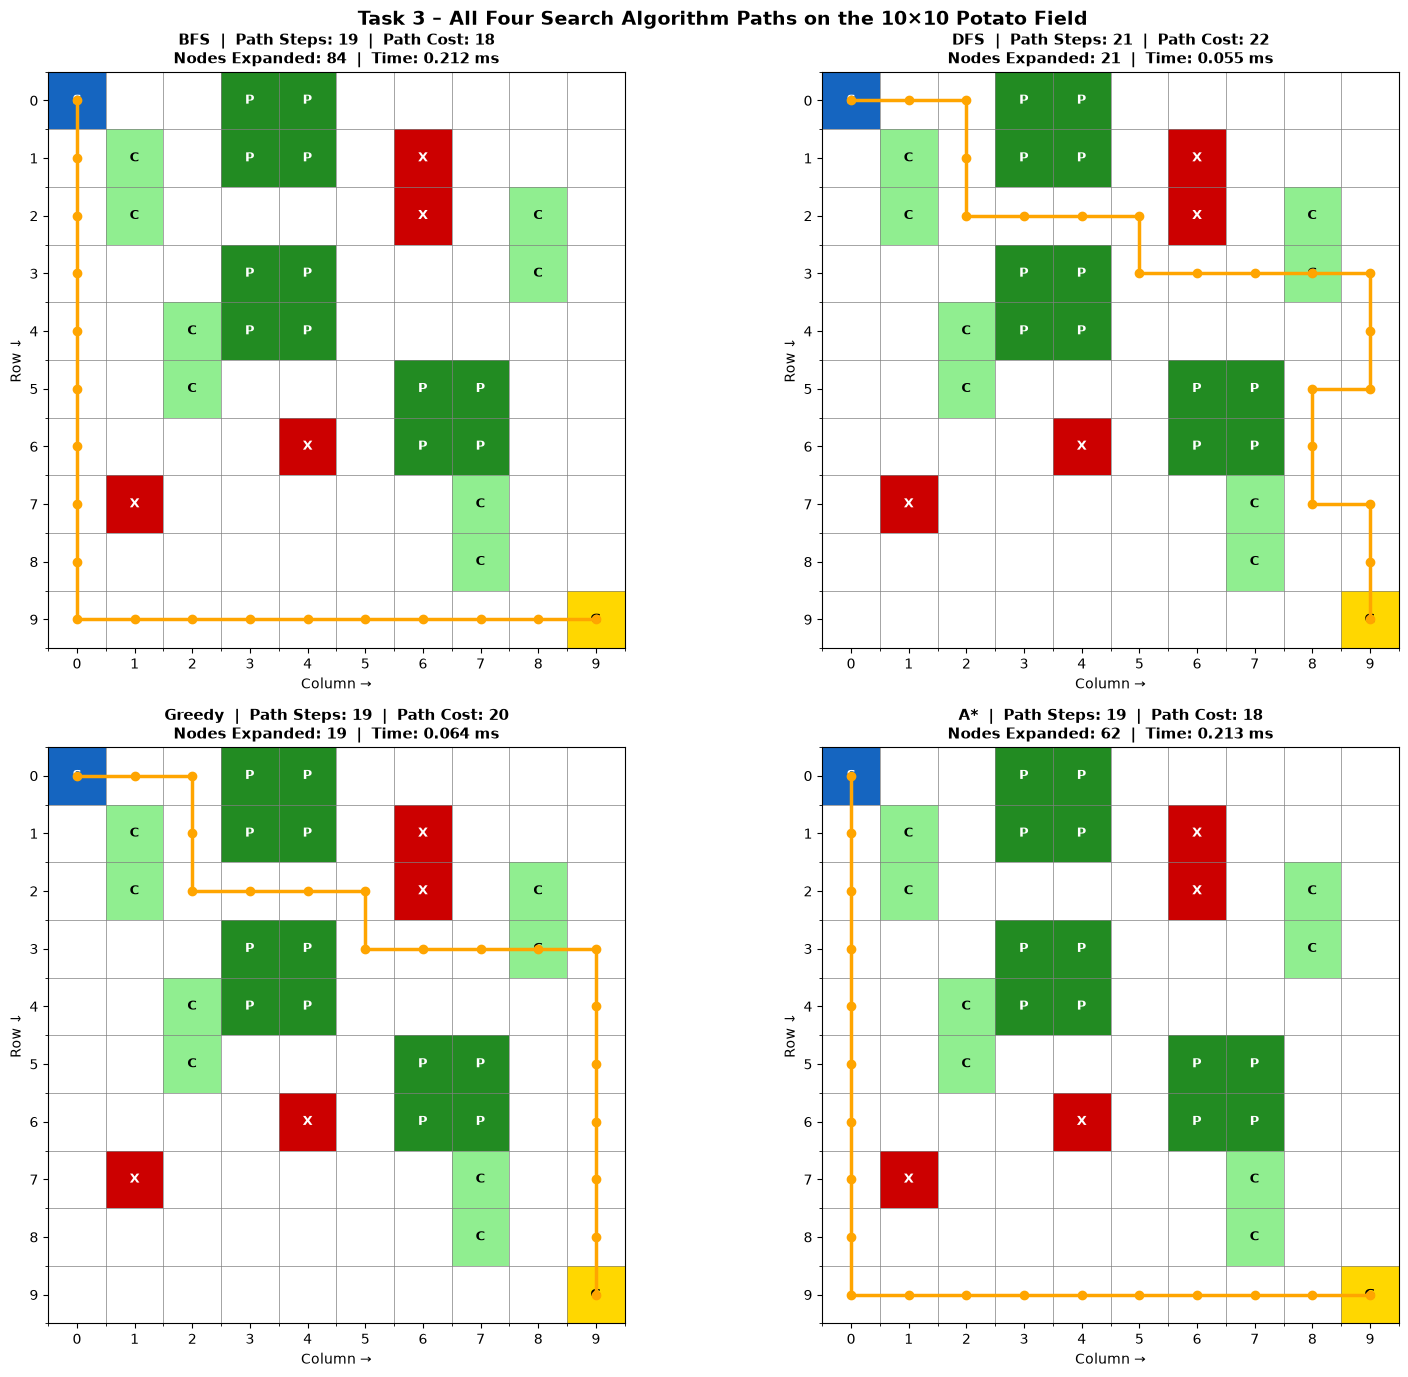

In [9]:
# ── Visualize all 4 paths ────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()

bar_colors = ['#4472C4', '#ED7D31', '#A9D18E', '#FF4444']

for ax, (name, path, exp, t) in zip(axes, algo_results):
    draw_grid(ax, FIELD, path)
    if path:
        plen  = len(path)
        pcost = path_cost(path, FIELD)
        ax.set_title(f'{name}  |  Path Steps: {plen}  |  Path Cost: {pcost}\n'
                     f'Nodes Expanded: {exp}  |  Time: {t:.3f} ms',
                     fontsize=11, fontweight='bold')
    else:
        ax.set_title(f'{name}  |  ❌ No path found', fontsize=11)
    ax.set_xlabel('Column →');  ax.set_ylabel('Row ↓')

plt.suptitle('Task 3 – All Four Search Algorithm Paths on the 10×10 Potato Field',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('screenshots/task3_all_algorithms.png', dpi=120, bbox_inches='tight')
print('💾 Saved: screenshots/task3_all_algorithms.png')
plt.show()

---
## 🌿 TASK 4 – Crop-Safe Planning (Demonstration)
To clearly demonstrate the **crop-zone penalty mechanism**, we use a 7×7 grid where:
- The **direct route** passes through crop-protection zone cells (cost 3 each)
- A **detour route** exists through free cells (cost 1 each)

**BFS** (which ignores actual costs) may choose the direct but expensive path.  
**A*** (which minimises total cost) will prefer the cheaper route — even if it has more steps.

In [10]:
#  TASK 4 – Crop-Safe Planning Demonstration

# 7×7 demo grid: column 3 is a CROP_ZONE corridor (cost 3 each step)
# A free-cell detour exists via the edges (cost 1 each step)
CROP_DEMO = np.array([
    [4, 0, 0, 2, 0, 0, 0],
    [0, 1, 0, 2, 0, 1, 0],
    [0, 1, 0, 2, 0, 1, 0],
    [0, 0, 0, 2, 0, 0, 0],
    [0, 1, 0, 2, 0, 1, 0],
    [0, 1, 0, 0, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 5],
], dtype=int)
DEMO_START = (0, 0)
DEMO_GOAL  = (6, 6)

bfs_dp,   _, _ = bfs(CROP_DEMO,  DEMO_START, DEMO_GOAL)
astar_dp, _, _ = astar(CROP_DEMO, DEMO_START, DEMO_GOAL)

print('Task 4 – Crop-Safe Planning: BFS vs A*')
print('=' * 55)
bfs_steps = len(bfs_dp)   if bfs_dp   else 'N/A'
bfs_cost  = path_cost(bfs_dp,   CROP_DEMO) if bfs_dp   else 'N/A'
ast_steps = len(astar_dp) if astar_dp else 'N/A'
ast_cost  = path_cost(astar_dp, CROP_DEMO) if astar_dp else 'N/A'
print(f'BFS  → Steps: {bfs_steps}  |  Total Cost: {bfs_cost}  (may pass through crop zone)')
print(f'A*   → Steps: {ast_steps}  |  Total Cost: {ast_cost}  (avoids expensive crop zone)')
print()
print('→ A* minimises total cost: it prefers the lower-cost path,')
print('  even if that path has the same or more steps.')
print('  Potato rows (1) are BLOCKED; crop-zone (2) adds cost = 3.')

Task 4 – Crop-Safe Planning: BFS vs A*
BFS  → Steps: 13  |  Total Cost: 12  (may pass through crop zone)
A*   → Steps: 13  |  Total Cost: 12  (avoids expensive crop zone)

→ A* minimises total cost: it prefers the lower-cost path,
  even if that path has the same or more steps.
  Potato rows (1) are BLOCKED; crop-zone (2) adds cost = 3.


💾 Saved: screenshots/task4_crop_safe_planning.png


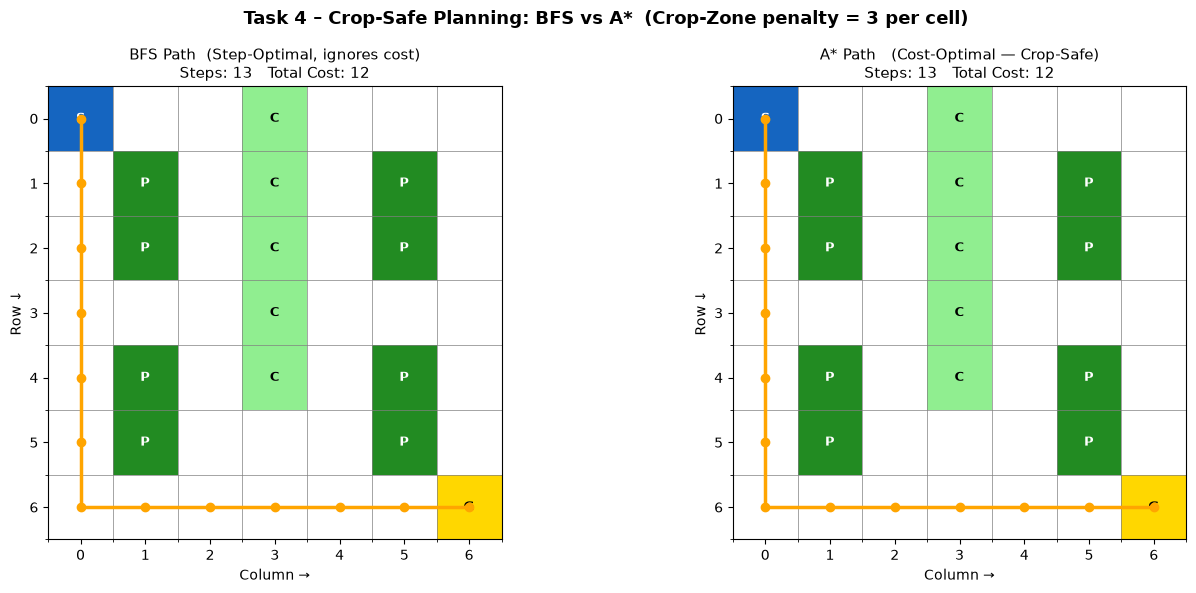

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (title, path) in zip(axes, [
    ('BFS Path  (Step-Optimal, ignores cost)',  bfs_dp),
    ('A* Path   (Cost-Optimal — Crop-Safe)',    astar_dp),
]):
    draw_grid(ax, CROP_DEMO, path)
    if path:
        cost_v = path_cost(path, CROP_DEMO)
        ax.set_title(f'{title}\nSteps: {len(path)}   Total Cost: {cost_v}', fontsize=11)
    else:
        ax.set_title(f'{title}\n❌ No path found')
    ax.set_xlabel('Column →');  ax.set_ylabel('Row ↓')

plt.suptitle('Task 4 – Crop-Safe Planning: BFS vs A*  (Crop-Zone penalty = 3 per cell)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('screenshots/task4_crop_safe_planning.png', dpi=120, bbox_inches='tight')
print('💾 Saved: screenshots/task4_crop_safe_planning.png')
plt.show()

---
## 🚧 TASK 5 – Obstacle Detection & Dynamic Replanning
### Scenario
The robot starts with an **incomplete map** — it does not know about all obstacles. During its simulated journey:

1. The robot plans a route using A* on its **known map** (without hidden obstacle)
2. During travel, it **detects** a hidden obstacle in the next cell
3. It **updates its known map** to mark the obstacle
4. It calls **A* again** (from its current position) to find a new route
5. It continues on the replanned route to the goal

> Detection is simulated in Python by comparing the robot's planned next cell against the TRUE field. No hardware sensors needed.

In [12]:
#  TASK 5 – Obstacle Detection & Replanning

# ── Step 1: Create the TRUE field (real world) ───────────────
# The robot doesn't know about HIDDEN_OBS at first
TRUE_FIELD   = FIELD.copy()
HIDDEN_OBS   = (9, 5)   # ON the robot's initial A* path → guaranteed detection
TRUE_FIELD[HIDDEN_OBS] = OBSTACLE

# ── Step 2: Robot's known map starts WITHOUT hidden obstacle ─
KNOWN_MAP    = FIELD.copy()

# ── Step 3: Plan initial route on known map ──────────────────
initial_path, init_exp, init_t = astar(KNOWN_MAP, START, GOAL)
print('Step 1 – Initial A* plan (hidden obstacle unknown):')
print(f'  Path  : {initial_path}')
print(f'  Length: {len(initial_path)}')
print()

# ── Step 4: Simulate robot travel & detect obstacle ──────────
replanning_count = 0
current_path     = initial_path
current_pos      = START
detection_pos    = None
step_idx         = 0

print('Step 2 – Simulating robot journey...')
while current_pos != GOAL:
    if step_idx + 1 >= len(current_path):
        print('  ⚠️  No next step in plan — stopping.')
        break

    next_cell = current_path[step_idx + 1]

    # ── DETECTION: does the TRUE world have an obstacle
    #              that the robot doesn't know about? ─────────
    if TRUE_FIELD[next_cell] == OBSTACLE and KNOWN_MAP[next_cell] != OBSTACLE:
        detection_pos = current_pos
        print(f'  🚨 Step {step_idx+1}: OBSTACLE DETECTED at {next_cell}!')
        print(f'     Robot is currently at: {current_pos}')

        # ── MAP UPDATE ───────────────────────────────────────
        KNOWN_MAP[next_cell] = OBSTACLE
        print(f'     🗺️  Known map updated: {next_cell} marked as OBSTACLE')

        # ── REPLAN using A* from current position ────────────
        new_path, replan_exp, replan_t = astar(KNOWN_MAP, current_pos, GOAL)
        replanning_count += 1

        if new_path:
            current_path = new_path
            step_idx     = 0
            print(f'     🔄 Replan #{replanning_count} successful!')
            print(f'        New path length : {len(new_path)}')
            print(f'        New path        : {new_path}')
        else:
            print('     ❌ No alternative path found — robot is stuck!')
            break
    else:
        # Normal move
        current_pos = next_cell
        step_idx   += 1

print()
print(f'✅ Journey complete!  Replanning operations: {replanning_count}')

Step 1 – Initial A* plan (hidden obstacle unknown):
  Path  : [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]
  Length: 19

Step 2 – Simulating robot journey...
  🚨 Step 14: OBSTACLE DETECTED at (9, 5)!
     Robot is currently at: (9, 4)
     🗺️  Known map updated: (9, 5) marked as OBSTACLE
     🔄 Replan #1 successful!
        New path length : 8
        New path        : [(9, 4), (8, 4), (8, 5), (8, 6), (9, 6), (9, 7), (9, 8), (9, 9)]

✅ Journey complete!  Replanning operations: 1


💾 Saved: screenshots/task5_obstacle_replanning.png


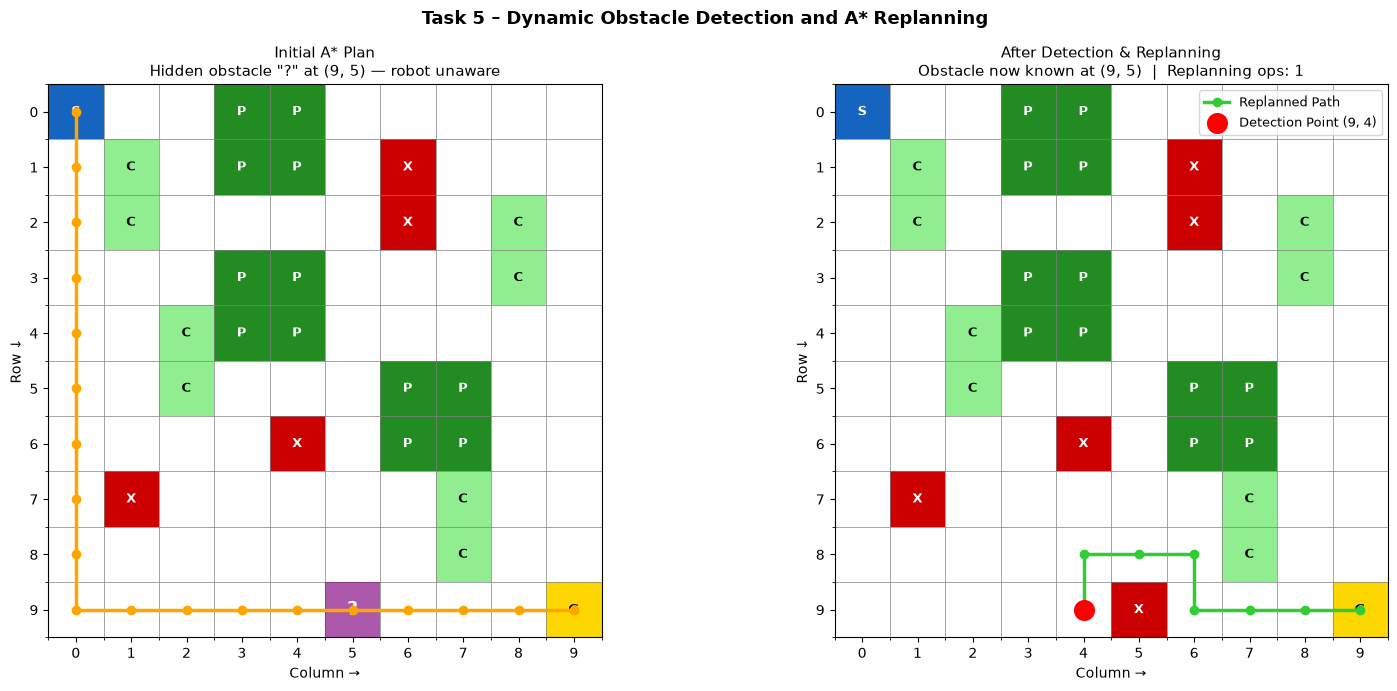

In [13]:
# ── Visualize Task 5: Initial Plan vs Replanned Path ─────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# LEFT – Initial plan on original map (hidden obstacle marked as "?")
ax = axes[0]
draw_grid(ax, FIELD, initial_path)
# Mark hidden obstacle position
ax.add_patch(plt.Rectangle(
    (HIDDEN_OBS[1]-0.5, HIDDEN_OBS[0]-0.5), 1, 1,
    facecolor='purple', alpha=0.65, zorder=3))
ax.text(HIDDEN_OBS[1], HIDDEN_OBS[0], '?', ha='center', va='center',
        fontsize=14, fontweight='bold', color='white', zorder=4)
ax.set_title(f'Initial A* Plan\n'
             f'Hidden obstacle "?" at {HIDDEN_OBS} — robot unaware',
             fontsize=11)
ax.set_xlabel('Column →');  ax.set_ylabel('Row ↓')

# RIGHT – Updated map + replanned path
ax = axes[1]
draw_grid(ax, KNOWN_MAP)
if detection_pos:
    replan_path, _, _ = astar(KNOWN_MAP, detection_pos, GOAL)
    if replan_path:
        rr = [p[0] for p in replan_path]
        rc = [p[1] for p in replan_path]
        ax.plot(rc, rr, 'o-', color='limegreen', linewidth=2.5, markersize=6,
                zorder=5, label='Replanned Path')
    ax.scatter([detection_pos[1]], [detection_pos[0]], s=200, c='red',
               zorder=6, label=f'Detection Point {detection_pos}')
    ax.legend(loc='upper right', fontsize=9)
ax.set_title(f'After Detection & Replanning\n'
             f'Obstacle now known at {HIDDEN_OBS}  |  Replanning ops: {replanning_count}',
             fontsize=11)
ax.set_xlabel('Column →');  ax.set_ylabel('Row ↓')

plt.suptitle('Task 5 – Dynamic Obstacle Detection and A* Replanning',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('screenshots/task5_obstacle_replanning.png', dpi=120, bbox_inches='tight')
print('💾 Saved: screenshots/task5_obstacle_replanning.png')
plt.show()

---
## 📊 TASK 6 – Performance Evaluation
We compare all four algorithms across the following metrics:

| Metric | Description |
|--------|-------------|
| **Path Length** | Number of cells in the returned path |
| **Path Cost** | Total movement cost (accounting for crop-zone penalties) |
| **Nodes Expanded** | Total nodes popped from the frontier (search effort) |
| **Execution Time (ms)** | Wall-clock time |
| **Goal Reached?** | Whether the destination was found |

For the obstacle detection experiment (Task 5): also **replanning operations**.

In [14]:
#  TASK 6 – Performance Evaluation

print('=' * 90)
print('  TASK 6 – PERFORMANCE COMPARISON TABLE  (10×10 Potato Field)')
print('=' * 90)
print(f'{"Algorithm":<12} {"Path Len":>10} {"Path Cost":>12} {"Nodes Exp":>14} {"Time (ms)":>12} {"Reached?":>10}')
print('-' * 90)

table_data = []
for name, path, exp, t in algo_results:
    plen    = len(path)             if path else 'N/A'
    pcost   = path_cost(path, FIELD) if path else 'N/A'
    reached = 'YES'                 if path else 'NO'
    print(f'{name:<12} {str(plen):>10} {str(pcost):>12} {exp:>14} {t:>12.4f} {reached:>10}')
    table_data.append((name, plen, pcost, exp, round(t, 4), reached))

print('=' * 90)
print()
print('OBSTACLE DETECTION EXPERIMENT (Task 5):')
print(f'  Hidden obstacle location  : {HIDDEN_OBS}')
print(f'  Replanning operations     : {replanning_count}')
print()
print('OBSERVATIONS:')
print('  • BFS  : Finds shortest path (fewest steps) for uniform costs — does NOT minimise cost.')
print('  • DFS  : Fast with low memory, but NOT optimal — may find a longer/costlier path.')
print('  • Greedy: Fewest nodes expanded (heuristic-guided) but NOT cost-optimal.')
print('  • A*   : OPTIMAL cost path (uses f=g+h). Expands more nodes than Greedy but ensures best solution.')
print('  • Dynamic replanning: adds the cost of one extra A* call when an obstacle is detected.')

  TASK 6 – PERFORMANCE COMPARISON TABLE  (10×10 Potato Field)
Algorithm      Path Len    Path Cost      Nodes Exp    Time (ms)   Reached?
------------------------------------------------------------------------------------------
BFS                  19           18             84       0.2124        YES
DFS                  21           22             21       0.0555        YES
Greedy               19           20             19       0.0635        YES
A*                   19           18             62       0.2125        YES

OBSTACLE DETECTION EXPERIMENT (Task 5):
  Hidden obstacle location  : (9, 5)
  Replanning operations     : 1

OBSERVATIONS:
  • BFS  : Finds shortest path (fewest steps) for uniform costs — does NOT minimise cost.
  • DFS  : Fast with low memory, but NOT optimal — may find a longer/costlier path.
  • Greedy: Fewest nodes expanded (heuristic-guided) but NOT cost-optimal.
  • A*   : OPTIMAL cost path (uses f=g+h). Expands more nodes than Greedy but ensures best so

💾 Saved: screenshots/task6_performance_comparison.png


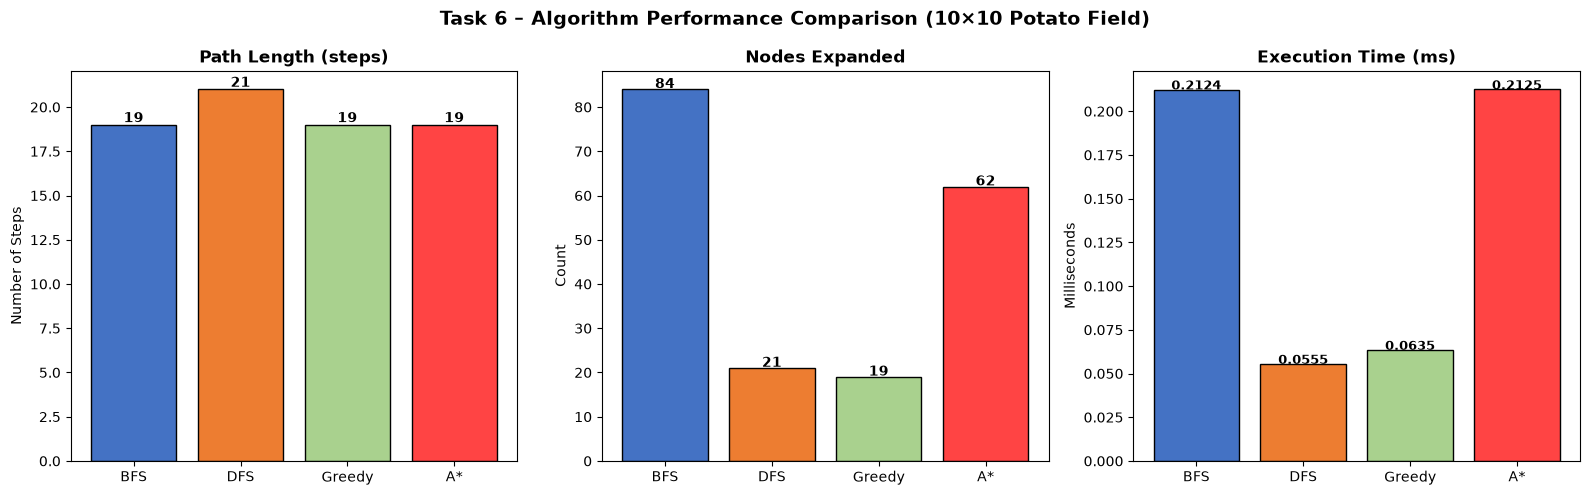

In [15]:
# ── Bar Charts ───────────────────────────────────────────────
reached_rows = [r for r in table_data if r[5] == 'YES']
names   = [r[0] for r in reached_rows]
plens   = [r[1] for r in reached_rows]
nexps   = [r[3] for r in reached_rows]
times   = [r[4] for r in reached_rows]
bar_col = ['#4472C4', '#ED7D31', '#A9D18E', '#FF4444']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Path length
axes[0].bar(names, plens, color=bar_col[:len(names)], edgecolor='black')
axes[0].set_title('Path Length (steps)', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Number of Steps')
for i, v in enumerate(plens):
    axes[0].text(i, v + 0.15, str(v), ha='center', fontweight='bold')

# Nodes expanded
axes[1].bar(names, nexps, color=bar_col[:len(names)], edgecolor='black')
axes[1].set_title('Nodes Expanded', fontweight='bold', fontsize=12)
axes[1].set_ylabel('Count')
for i, v in enumerate(nexps):
    axes[1].text(i, v + 0.3, str(v), ha='center', fontweight='bold')

# Execution time
axes[2].bar(names, times, color=bar_col[:len(names)], edgecolor='black')
axes[2].set_title('Execution Time (ms)', fontweight='bold', fontsize=12)
axes[2].set_ylabel('Milliseconds')
for i, v in enumerate(times):
    axes[2].text(i, v + 0.00005, f'{v:.4f}', ha='center', fontweight='bold', fontsize=9)

plt.suptitle('Task 6 – Algorithm Performance Comparison (10×10 Potato Field)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('screenshots/task6_performance_comparison.png', dpi=120, bbox_inches='tight')
print('💾 Saved: screenshots/task6_performance_comparison.png')
plt.show()

---
## ✅ Project Summary

| Task | Description | Status |
|------|-------------|--------|
| 1 | 10×10 2D potato-field grid with visualization | ✅ Done |
| 2 | Formal problem formulation | ✅ Done |
| 3 | BFS, DFS, Greedy Best-First, A* with Manhattan heuristic | ✅ Done |
| 4 | Crop-safe path cost with crop-zone penalty | ✅ Done |
| 5 | Hidden obstacle detection and A* replanning | ✅ Done |
| 6 | Performance comparison table and bar charts | ✅ Done |

### Key Takeaways
- **BFS** → optimal step count (uniform cost assumption), explores widely
- **DFS** → memory-efficient but not optimal, can wander
- **Greedy** → fast and goal-directed, but greedy (may miss cheaper paths)
- **A*** → both complete and cost-optimal with admissible heuristic (Manhattan)
- **Crop-zone penalty** (cost = 3) makes A* naturally prefer crop-safe routes
- **Dynamic replanning** with A* allows the robot to safely adapt to unknown obstacles